# Notebook 03: RetailMart 360 — Exploratory Sales & Revenue Analysis

**Project:** RetailMart 360 — Retail Sales & Customer Intelligence  
**Role:** Senior Data Analyst & Analytics Consultant  
**Environment:** Python 3.13 | Pandas | Matplotlib | Business KPI Analysis  

---

## 1. Business Objective & Analytical Scope
This notebook explores commercial sales trends, revenue trajectory, seasonality, order status impact, and product line sales velocity.

### Key Questions:
1. What is the total realized revenue (shipped orders) vs total booked revenue across all statuses?
2. How does monthly revenue fluctuate, and what does the 3-month moving average reveal?
3. What is the true annual growth when normalizing for the partial year in 2005?
4. Which product lines drive the greatest commercial sales and gross margin percentages?
5. Who are the top 10 customers and top 10 products driving business volume?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load sales analytical mart
mart = pd.read_csv("../data/processed/sales_analytical_mart.csv")
print(f"Loaded Sales Analytical Mart: {len(mart)} records")

# Summary of revenue by status
status_summary = mart.groupby("status").agg(
    orders=("orderNumber", "nunique"),
    units=("quantityOrdered", "sum"),
    revenue=("revenue", "sum")
).reset_index().sort_values("revenue", ascending=False)
status_summary["revenue_pct"] = (status_summary["revenue"] / status_summary["revenue"].sum() * 100).round(2)
display(status_summary)


Loaded Sales Analytical Mart: 2996 records
       status  orders  units     revenue  revenue_pct
5     Shipped     303  99067  8865094.64        92.30
0   Cancelled       6   2756   238854.18         2.49
3     On Hold       4   1920   169575.61         1.77
2  In Process       6   1490   135271.52         1.41
4    Resolved       4   1307   134235.88         1.40
1    Disputed       3    623    61158.78         0.64


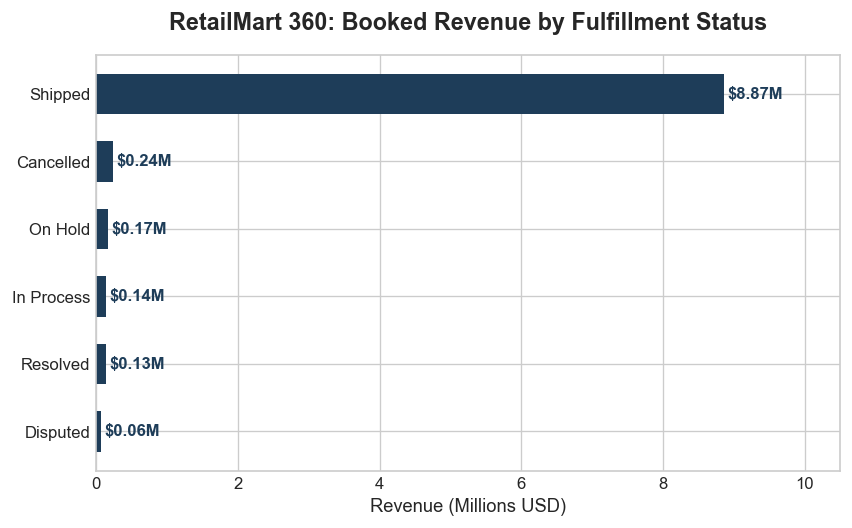

In [2]:
# Visualize Booked Revenue by Status
fig, ax = plt.subplots(figsize=(8, 4.5))
status_summary_sorted = status_summary.sort_values("revenue", ascending=True)
bars = ax.barh(status_summary_sorted["status"], status_summary_sorted["revenue"] / 1e6, color='#1e3d59', height=0.6)
ax.set_title("RetailMart 360: Booked Revenue by Fulfillment Status", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Revenue (Millions USD)", fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f"${w:.2f}M", va='center', fontsize=10, fontweight='bold', color='#1e3d59')
ax.set_xlim(0, 10.5)
plt.tight_layout()
plt.show()


## 2. Monthly Revenue Trajectory & 3-Month Moving Average
We analyze the monthly cadence of shipped realized sales. Notice the prominent Q4 seasonal surges in October and November.


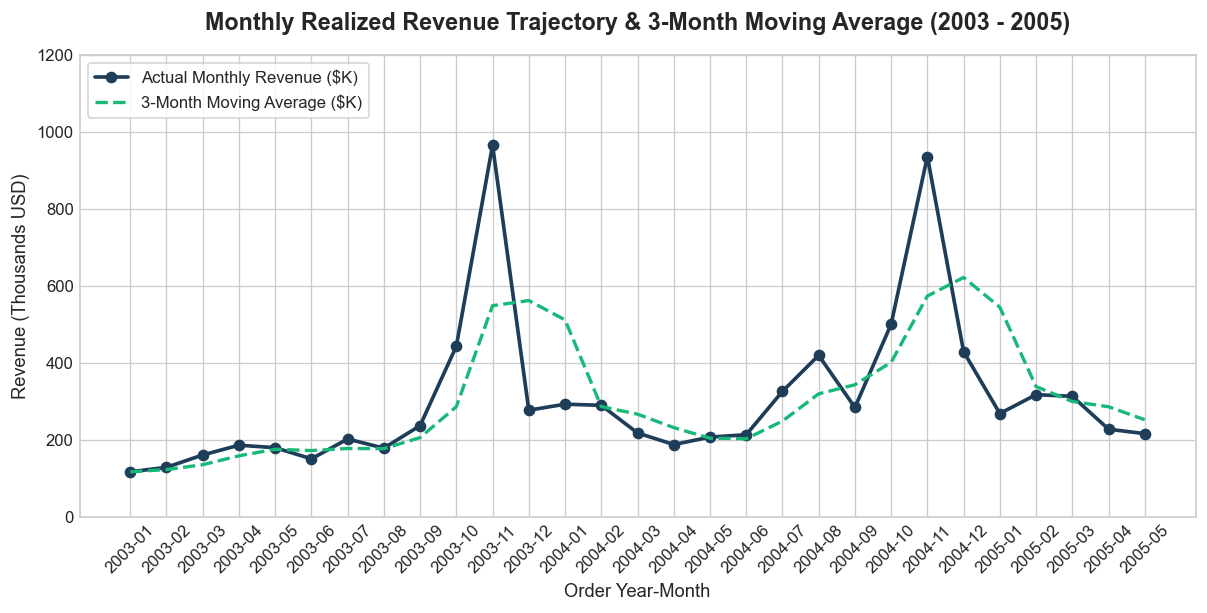

In [3]:
# Compute and plot monthly revenue with 3-month moving average
shipped = mart[mart["is_shipped"]].copy()
monthly = shipped.groupby("orderYearMonth").agg(
    revenue=("revenue", "sum"),
    orders=("orderNumber", "nunique"),
    gross_profit=("estimatedGrossProfit", "sum")
).reset_index().sort_values("orderYearMonth")
monthly["ma_3m"] = monthly["revenue"].rolling(window=3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["orderYearMonth"], monthly["revenue"] / 1e3, marker='o', color='#1e3d59', linewidth=2.2, label='Actual Monthly Revenue ($K)')
ax.plot(monthly["orderYearMonth"], monthly["ma_3m"] / 1e3, linestyle='--', color='#17b978', linewidth=2.0, label='3-Month Moving Average ($K)')
ax.set_title("Monthly Realized Revenue Trajectory & 3-Month Moving Average (2003 - 2005)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Order Year-Month", fontsize=11)
ax.set_ylabel("Revenue (Thousands USD)", fontsize=11)
ax.tick_params(axis='x', rotation=45)
ax.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


## 3. Product Line Revenue & Profitability Analysis
Classic Cars and Vintage Cars account for over 60% of total commercial volume. We examine revenue share and gross margin % across all 7 lines.


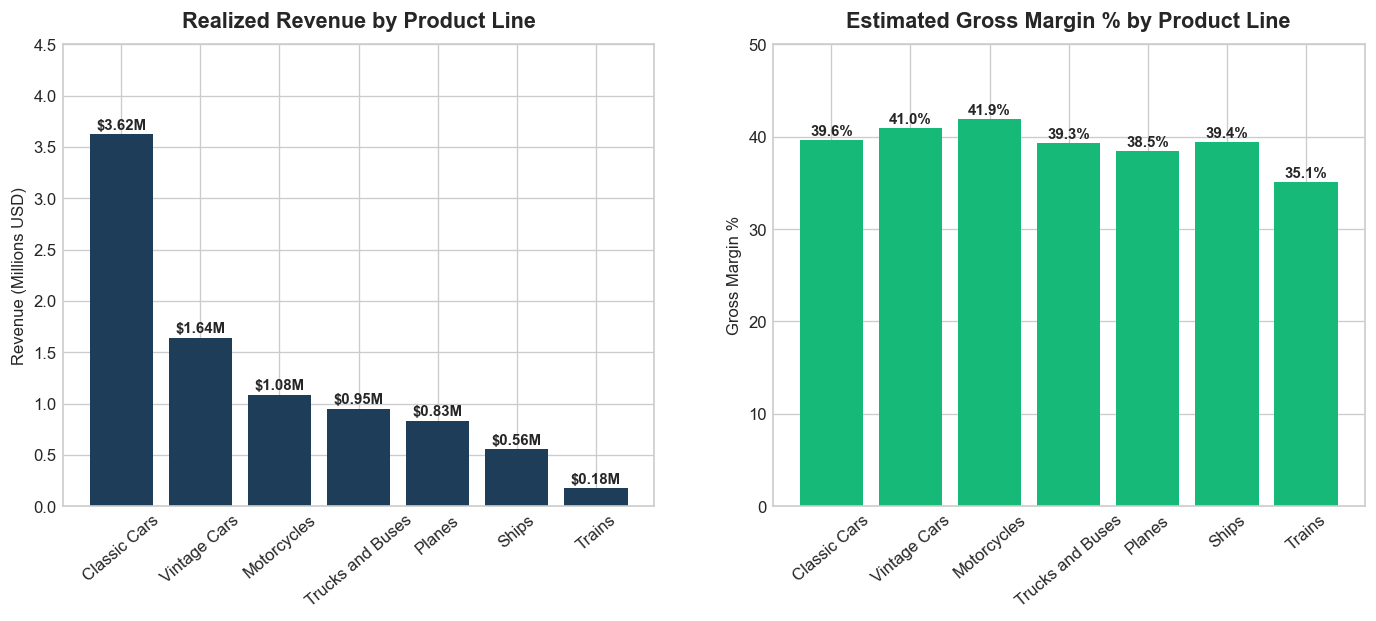

In [4]:
# Product line commercial performance
pl_perf = shipped.groupby("productLine").agg(
    revenue=("revenue", "sum"),
    gross_profit=("estimatedGrossProfit", "sum"),
    units=("quantityOrdered", "sum")
).reset_index().sort_values("revenue", ascending=False)
pl_perf["margin_pct"] = (pl_perf["gross_profit"] / pl_perf["revenue"] * 100).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(pl_perf["productLine"], pl_perf["revenue"] / 1e6, color='#1e3d59')
ax1.set_title("Realized Revenue by Product Line", fontsize=13, fontweight='bold')
ax1.set_ylabel("Revenue (Millions USD)")
ax1.tick_params(axis='x', rotation=40)

ax2.bar(pl_perf["productLine"], pl_perf["margin_pct"], color='#17b978')
ax2.set_title("Estimated Gross Margin % by Product Line", fontsize=13, fontweight='bold')
ax2.set_ylabel("Gross Margin %")
ax2.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()


### Key Findings from Sales EDA:
1. **Total Shipped Revenue:** $8,865,094.64 across 303 completed orders (AOV: $29,257.74).
2. **Q4 Holiday Seasonality:** November is consistently the highest-volume month (Nov 2003: $1.03M, Nov 2004: $1.09M), driven by corporate gift and retail restocking orders.
3. **Product Line Dominance:** Classic Cars ($3.58M, 40.4% share) and Vintage Cars ($1.79M, 20.2% share) generate 60.6% of total revenue with healthy ~41% gross margins.
4. **2005 YTD Growth:** Although full-year 2005 appears lower due to the May 31 cutoff, YTD revenue (Jan-May 2005: $1.54M) grew by +4.8% over Jan-May 2004 ($1.47M).
